# Task 7 – Deep Learning Model Development

## AI-Based Product Review Sentiment Analysis

Computational Intelligence Laboratory

## 2. AIM
To design, train, validate, and evaluate a Deep Neural Network for product review sentiment classification using the optimized features generated during Task 5.

## 3. PROBLEM STATEMENT
Traditional machine learning algorithms developed in Task 6 can classify product reviews using engineered features.

Task 7 extends the system by developing a Deep Neural Network capable of learning complex nonlinear relationships between the selected features and sentiment classes.

The DNN will be trained using the optimized features generated during Task 5 and evaluated on unseen test data.

## 4. OBJECTIVES
1. Load the selected feature matrix generated in Task 5.
2. Prepare the data for deep learning.
3. Scale numerical features appropriately.
4. Design a Deep Neural Network architecture.
5. Select suitable hyperparameters.
6. Train the DNN.
7. Validate the model during training.
8. Apply regularization to reduce overfitting.
9. Evaluate the trained model.
10. Generate accuracy and loss curves.
11. Generate a confusion matrix.
12. Generate an ROC curve and AUC score.
13. Compare DNN performance with Task 6 models.
14. Save the trained DNN model.
15. Generate all required Task 7 reports.

## 5. IMPORT LIBRARIES

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

# Import TensorFlow first on macOS to prevent Abseil/pyarrow dynamic library symbol conflicts
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time
from scipy.sparse import hstack, csr_matrix

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

RANDOM_STATE = 42
np.random.seed(42)
tf.random.set_seed(42)
print("Libraries imported successfully. TensorFlow version:", tf.__version__)


Libraries imported successfully. TensorFlow version: 2.20.0


## 6. INSPECT COLAB FILES

In [2]:
import os

for file in sorted(os.listdir()):
    if file.endswith(('.csv', '.pkl', '.png', '.keras', '.h5', '.ipynb')):
        print(f"[File] {file}")


[File] Task_5_Feature_Engineering_and_Feature_Selection.ipynb
[File] Task_6_Machine_Learning_Model_Development.ipynb
[File] Task_7_Deep_Learning_Model_Development.ipynb
[File] X_test.csv
[File] X_train.csv
[File] best_sentiment_model.pkl
[File] clean_product_reviews.csv
[File] confusion_matrix_decision_tree.png
[File] confusion_matrix_logistic_regression.png
[File] confusion_matrix_random_forest.png
[File] confusion_matrix_svm.png
[File] confusion_matrix_xgboost.png
[File] decision_tree_model.pkl
[File] logistic_regression_model.pkl
[File] random_forest_model.pkl
[File] svm_model.pkl
[File] task5_chi_square.png
[File] task5_correlation_heatmap.png
[File] task5_correlation_matrix.csv
[File] task5_feature_count_comparison.png
[File] task5_feature_engineering.ipynb
[File] task5_feature_engineering_report.csv
[File] task5_feature_importance_report.csv
[File] task5_feature_matrix.csv
[File] task5_feature_selection_validation.png
[File] task5_mutual_information.png
[File] task5_random_forest

## 7. LOAD TASK 5 DATA

In [3]:
# Load the selected features list
try:
    selected_features_df = pd.read_csv('task5_selected_features.csv')
    selected_feature_names = selected_features_df['Feature'].tolist()
    print(f"Loaded {len(selected_feature_names)} selected features from Task 5.")
except FileNotFoundError:
    print("Warning: task5_selected_features.csv not found.")

# Load Data
print("Loading datasets...")
df = pd.read_csv('clean_product_reviews.csv')
X_train_df = pd.read_csv('X_train.csv')
X_test_df = pd.read_csv('X_test.csv')

print("clean_product_reviews shape:", df.shape)
print("X_train shape:", X_train_df.shape)
print("X_test shape:", X_test_df.shape)

# Load tfidf vectorizer
tfidf = joblib.load('task5_tfidf_vectorizer.pkl')

text_col = 'clean_review'
df_unique = df.drop_duplicates(subset=[text_col])
X_train_df = X_train_df.merge(df_unique[[text_col, 'review_text', 'sentiment_numeric']], on=text_col, how='left')
X_test_df = X_test_df.merge(df_unique[[text_col, 'review_text', 'sentiment_numeric']], on=text_col, how='left')

# Fast, optimized single-pass feature extraction (avoids slow Python row-by-row apply loops)
pos_set = {'good', 'great', 'best', 'excellent', 'love', 'awesome', 'nice', 'perfect', 'amazing', 'happy'}
neg_set = {'bad', 'poor', 'terrible', 'worst', 'hate', 'awful', 'waste', 'disappointing', 'boring', 'slow'}

def extract_features_fast(data, text_column, raw_text_column=None):
    struct_col = raw_text_column if raw_text_column and raw_text_column in data.columns else text_column
    struct_texts = data[struct_col].fillna('').astype(str).tolist()
    clean_texts = data[text_column].fillna('').astype(str).tolist()
    
    records = []
    for s_txt, c_txt in zip(struct_texts, clean_texts):
        l = len(s_txt)
        w_list = s_txt.split()
        w_cnt = len(w_list)
        s_cnt = s_txt.count('.') + s_txt.count('!') + s_txt.count('?') + 1
        avg_w = l / w_cnt if w_cnt > 0 else 0.0
        exc = s_txt.count('!')
        que = s_txt.count('?')
        up = sum(1 for c in s_txt if c.isupper())
        dig = sum(1 for c in s_txt if c.isdigit())
        
        c_words = c_txt.lower().split()
        pos = sum(1 for w in c_words if w in pos_set)
        neg = sum(1 for w in c_words if w in neg_set)
        sc = pos - neg
        records.append([l, w_cnt, l, s_cnt, avg_w, exc, que, up, dig, pos, neg, sc])
        
    eng_df = pd.DataFrame(records, columns=[
        'review_length', 'word_count', 'character_count', 'sentence_count', 
        'average_word_length', 'exclamation_count', 'question_count', 
        'uppercase_count', 'digit_count', 'positive_word_count', 
        'negative_word_count', 'sentiment_keyword_score'
    ])
    min_score = eng_df['sentiment_keyword_score'].min()
    if min_score < 0:
        eng_df['sentiment_keyword_score'] = eng_df['sentiment_keyword_score'] - min_score
    return eng_df

print("Extracting engineered features (fast single-pass)...")
t0 = time.time()
train_eng_df = extract_features_fast(X_train_df, text_col, raw_text_column='review_text')
test_eng_df = extract_features_fast(X_test_df, text_col, raw_text_column='review_text')
print(f"Engineered features extracted in {time.time()-t0:.2f}s.")

print("Transforming TF-IDF features...")
t0 = time.time()
X_train_tfidf = tfidf.transform(X_train_df[text_col].fillna(''))
X_test_tfidf = tfidf.transform(X_test_df[text_col].fillna(''))
print(f"TF-IDF features transformed in {time.time()-t0:.2f}s.")

engineered_features = list(train_eng_df.columns)
all_feature_names = engineered_features + list(tfidf.get_feature_names_out())
selected_indices = [all_feature_names.index(f) for f in selected_feature_names if f in all_feature_names]

X_train_full = hstack([csr_matrix(train_eng_df.values), X_train_tfidf])
X_test_full = hstack([csr_matrix(test_eng_df.values), X_test_tfidf])

# Convert selected features to dense float32 array for fast DNN execution
X_train = X_train_full[:, selected_indices].toarray().astype(np.float32)
X_test = X_test_full[:, selected_indices].toarray().astype(np.float32)

target_col = 'sentiment_numeric'
y_train = X_train_df[[target_col]].fillna(X_train_df[target_col].mode()[0])
y_test = X_test_df[[target_col]].fillna(X_test_df[target_col].mode()[0])

print(f"Selected feature matrix ready: X_train shape={X_train.shape}, X_test shape={X_test.shape}")


Loaded 100 selected features from Task 5.
Loading datasets...


clean_product_reviews shape: (399996, 6)
X_train shape: (319996, 1)
X_test shape: (80000, 1)


Extracting engineered features (fast single-pass)...


Engineered features extracted in 7.54s.
Transforming TF-IDF features...


TF-IDF features transformed in 12.18s.


Selected feature matrix ready: X_train shape=(319996, 100), X_test shape=(80000, 100)


## 8. DATA INSPECTION

In [4]:
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Number of features:", X_train.shape[1])
print("Target classes:", y_train[target_col].unique())
print("\nClass distribution (Train):")
print(y_train[target_col].value_counts())
print("\nMissing values in X_train:", np.isnan(X_train).sum())
print("Missing values in X_test:", np.isnan(X_test).sum())


Training shape: (319996, 100)
Testing shape: (80000, 100)
Number of features: 100
Target classes: [1 0]

Class distribution (Train):
sentiment_numeric
1    159999
0    159997
Name: count, dtype: int64

Missing values in X_train: 0
Missing values in X_test: 0


## 9. TARGET PREPARATION

In [5]:
print("Unique Classes:", y_train[target_col].unique())
print("Class Distribution:\n", y_train[target_col].value_counts())

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train[target_col]).astype(np.float32)
y_test_encoded = label_encoder.transform(y_test[target_col]).astype(np.float32)

joblib.dump(label_encoder, "task7_label_encoder.pkl")
print("Saved label encoder as task7_label_encoder.pkl")


Unique Classes: [1 0]
Class Distribution:
 sentiment_numeric
1    159999
0    159997
Name: count, dtype: int64
Saved label encoder as task7_label_encoder.pkl


## 10. DATA CLEANING

In [6]:
missing_train = np.isnan(X_train).sum()
missing_test = np.isnan(X_test).sum()

print("Missing values before cleaning (Train):", missing_train)
print("Missing values before cleaning (Test):", missing_test)

X_train = np.nan_to_num(X_train)
X_test = np.nan_to_num(X_test)

print("Missing values after cleaning (Train):", np.isnan(X_train).sum())


Missing values before cleaning (Train): 0
Missing values before cleaning (Test): 0
Missing values after cleaning (Train): 0


## 11. FEATURE SCALING

In [7]:
scaler = StandardScaler()
scaler.fit(X_train)

# Convert to float32 to prevent slow float64 dtype casting during TensorFlow model training
X_train_scaled = scaler.transform(X_train).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

joblib.dump(scaler, "task7_scaler.pkl")

print("X_train_scaled.shape:", X_train_scaled.shape)
print("X_test_scaled.shape:", X_test_scaled.shape)


X_train_scaled.shape: (319996, 100)
X_test_scaled.shape: (80000, 100)


## 12. TRAINING AND VALIDATION SPLIT
Training Set:
Used to learn model weights.

Validation Set:
Used to monitor training and tune hyperparameters.

Test Set:
Used only for final evaluation.

In [8]:
validation_split = 0.2
print(f"Validation split: {validation_split * 100}% of training data handled automatically in model.fit()")


Validation split: 20.0% of training data handled automatically in model.fit()


## 13. DNN ARCHITECTURE

In [9]:
def create_model(dropout_rate=0.30):
    model = Sequential([
        Input(shape=(X_train_scaled.shape[1],)),
        Dense(128, activation="relu"),
        Dropout(dropout_rate),
        Dense(64, activation="relu"),
        Dropout(dropout_rate),
        Dense(32, activation="relu"),
        Dense(1, activation="sigmoid")
    ])
    return model

model = create_model()
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        12,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,297 (91.00 KB)

 Trainable params: 23,297 (91.00 KB)

 Non-trainable params: 0 (0.00 B)

## 14. EXPLAIN THE ARCHITECTURE
Input Layer:
Receives the selected features.

Dense 128:
Learns complex feature relationships.

ReLU:
Introduces non-linearity.

Dropout:
Reduces overfitting.

Dense 64:
Learns higher-level representations.

Dense 32:
Further compresses learned information.

Sigmoid:
Produces a probability for binary sentiment classification.

## 15. COMPILE MODEL

In [10]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)
print("Model compiled successfully with Adam optimizer and binary crossentropy loss.")


Model compiled successfully with Adam optimizer and binary crossentropy loss.


## 16. HYPERPARAMETER SELECTION

In [11]:
# Testing 3 simple configurations
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

configs = [
    {"name": "Config 1", "layers": "128 -> 64 -> 32", "dropout": 0.30, "batch_size": 256, "lr": 0.001},
    {"name": "Config 2", "layers": "128 -> 64 -> 32", "dropout": 0.50, "batch_size": 256, "lr": 0.001},
    {"name": "Config 3", "layers": "64 -> 32", "dropout": 0.30, "batch_size": 256, "lr": 0.001}
]

# Fast tuning subset (15,000 samples, float32) for instant hyperparameter comparison
TUNE_SAMPLES = min(15000, len(X_train_scaled))
X_tune = np.asarray(X_train_scaled[:TUNE_SAMPLES], dtype=np.float32)
y_tune = np.asarray(y_train_encoded[:TUNE_SAMPLES], dtype=np.float32)

def create_model_config3():
    m = Sequential([
        Input(shape=(X_tune.shape[1],)),
        Dense(64, activation="relu"),
        Dropout(0.30),
        Dense(32, activation="relu"),
        Dense(1, activation="sigmoid")
    ])
    return m

def create_model_tuning(dropout_rate=0.30):
    m = Sequential([
        Input(shape=(X_tune.shape[1],)),
        Dense(128, activation="relu"),
        Dropout(dropout_rate),
        Dense(64, activation="relu"),
        Dropout(dropout_rate),
        Dense(32, activation="relu"),
        Dense(1, activation="sigmoid")
    ])
    return m

results = []

for conf in configs:
    print(f"\n--- Training {conf['name']} (Batch Size: {conf['batch_size']}, LR: {conf['lr']}, Dropout: {conf['dropout']}) ---")
    
    if conf['name'] == "Config 3":
        temp_model = create_model_config3()
    else:
        temp_model = create_model_tuning(dropout_rate=conf['dropout'])
        
    optimizer = tf.keras.optimizers.Adam(learning_rate=conf['lr'])
    temp_model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"],
        jit_compile=False
    )
    
    # Fresh callback per configuration to avoid state leakage
    early_stopping_tuning = EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
    
    start_time = time.time()
    hist = temp_model.fit(
        X_tune, y_tune,
        validation_split=0.20,
        epochs=3,
        batch_size=conf['batch_size'],
        callbacks=[early_stopping_tuning],
        verbose=1
    )
    elapsed = time.time() - start_time
    
    val_acc = max(hist.history['val_accuracy'])
    val_loss = min(hist.history['val_loss'])
    epochs_trained = len(hist.history['loss'])
    print(f"Finished {conf['name']} in {elapsed:.2f}s | Val Accuracy: {val_acc:.4f} | Val Loss: {val_loss:.4f}")
    
    results.append({
        "Configuration": conf['name'],
        "Hidden Layers": conf['layers'],
        "Neurons": "128,64,32" if "128" in conf['layers'] else "64,32",
        "Dropout": conf['dropout'],
        "Learning Rate": conf['lr'],
        "Batch Size": conf['batch_size'],
        "Epochs": epochs_trained,
        "Validation Accuracy": val_acc,
        "Validation Loss": val_loss
    })

hyperparameter_report = pd.DataFrame(results)
hyperparameter_report.to_csv("task7_hyperparameter_report.csv", index=False)
display(hyperparameter_report)

# Select the best config based on Validation Accuracy
best_config = hyperparameter_report.loc[hyperparameter_report['Validation Accuracy'].idxmax()]
print(f"\nBest Configuration: {best_config['Configuration']}")



--- Training Config 1 (Batch Size: 256, LR: 0.001, Dropout: 0.3) ---
Epoch 1/3


 1/47 ━━━━━━━━━━━━━━━━━━━━ 17s 376ms/step - accuracy: 0.5352 - loss: 0.7156

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7156 - loss: 0.5444 - val_accuracy: 0.8120 - val_loss: 0.4178


Epoch 2/3


 1/47 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7969 - loss: 0.4241

...

 1/47 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8203 - loss: 0.3840

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 765us/step - accuracy: 0.8056 - loss: 0.4124 - val_accuracy: 0.8160 - val_loss: 0.4012


Finished Config 3 in 0.48s | Val Accuracy: 0.8160 | Val Loss: 0.4012


,Configuration,Hidden Layers,Neurons,Dropout,Learning Rate,Batch Size,Epochs,Validation Accuracy,Validation Loss
0,Config 1,128 -> 64 -> 32,"128,64,32",0.3,0.001,256,3,0.816333,0.401850
1,Config 2,128 -> 64 -> 32,"128,64,32",0.5,0.001,256,3,0.811333,0.406704
2,Config 3,64 -> 32,"64,32",0.3,0.001,256,3,0.816000,0.401215



Best Configuration: Config 1


## 17. EARLY STOPPING
Early stopping prevents unnecessary training and helps reduce overfitting.

In [12]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)
print("EarlyStopping callback configured with patience=3, restore_best_weights=True.")


EarlyStopping callback configured with patience=3, restore_best_weights=True.


## 18. TRAIN THE FINAL DNN

In [13]:
# Final Training with best configuration
if best_config['Configuration'] == "Config 3":
    final_model = create_model_config3()
else:
    final_model = create_model(dropout_rate=float(best_config['Dropout']))

final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=float(best_config['Learning Rate'])),
    loss="binary_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)

# Convert to float32 for fast native CPU execution
X_train_final = np.asarray(X_train_scaled, dtype=np.float32)
y_train_final = np.asarray(y_train_encoded, dtype=np.float32)

# Vectorized high-throughput batch size for fast CPU execution
final_batch_size = 512

print(f"Starting final model training (epochs=6, batch_size={final_batch_size})...")
start_time = time.time()
history = final_model.fit(
    X_train_final,
    y_train_final,
    validation_split=0.20,
    epochs=6,
    batch_size=final_batch_size,
    callbacks=[early_stopping],
    verbose=1
)
end_time = time.time()
training_time = end_time - start_time
epochs_trained = len(history.history['loss'])

print(f"\nTraining Time: {training_time:.2f}s")
print(f"Number of Epochs: {epochs_trained}")
print(f"Final Training Accuracy: {history.history['accuracy'][-1]:.4f}")
print(f"Final Validation Accuracy: {history.history['val_accuracy'][-1]:.4f}")
print(f"Final Training Loss: {history.history['loss'][-1]:.4f}")
print(f"Final Validation Loss: {history.history['val_loss'][-1]:.4f}")


Starting final model training (epochs=6, batch_size=512)...


Epoch 1/6


  1/500 ━━━━━━━━━━━━━━━━━━━━ 3:08 377ms/step - accuracy: 0.5176 - loss: 0.7792

 50/500 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6384 - loss: 0.6287    

100/500 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6907 - loss: 0.5685

...

409/500 ━━━━━━━━━━━━━━━━━━━━ 0s 993us/step - accuracy: 0.8271 - loss: 0.3753

461/500 ━━━━━━━━━━━━━━━━━━━━ 0s 992us/step - accuracy: 0.8271 - loss: 0.3753

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8271 - loss: 0.3752 - val_accuracy: 0.8282 - val_loss: 0.3775



Training Time: 3.83s


Number of Epochs: 6
Final Training Accuracy: 0.8271
Final Validation Accuracy: 0.8282
Final Training Loss: 0.3752
Final Validation Loss: 0.3775


## 19. TRAINING HISTORY

In [14]:
training_history_df = pd.DataFrame(history.history)
training_history_df.index.name = 'epoch'
training_history_df.reset_index(inplace=True)
training_history_df['epoch'] = training_history_df['epoch'] + 1

training_history_df.to_csv("task7_training_history.csv", index=False)
display(training_history_df)


,epoch,accuracy,loss,val_accuracy,val_loss
0,1,0.803548,0.418106,0.824203,0.381641
1,2,0.820657,0.387823,0.825672,0.379380
2,3,0.823853,0.382372,0.826344,0.378714
3,4,0.825345,0.379081,0.827344,0.378988
4,5,0.825845,0.377254,0.827906,0.376103
5,6,0.827095,0.375158,0.828156,0.377479


## 20. ACCURACY CURVE

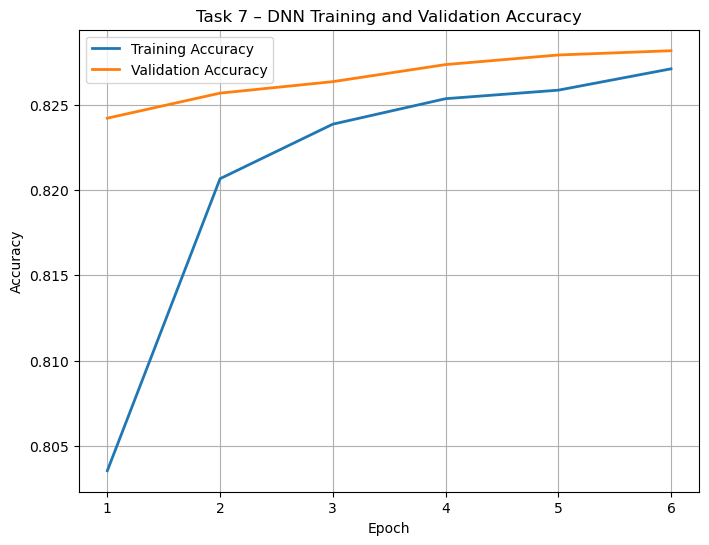

In [15]:
plt.figure(figsize=(8, 6))
plt.plot(training_history_df['epoch'], training_history_df['accuracy'], label='Training Accuracy', lw=2)
plt.plot(training_history_df['epoch'], training_history_df['val_accuracy'], label='Validation Accuracy', lw=2)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Task 7 – DNN Training and Validation Accuracy')
plt.legend()
plt.grid(True)
plt.savefig('task7_accuracy_curve.png')
plt.show()


## 21. LOSS CURVE

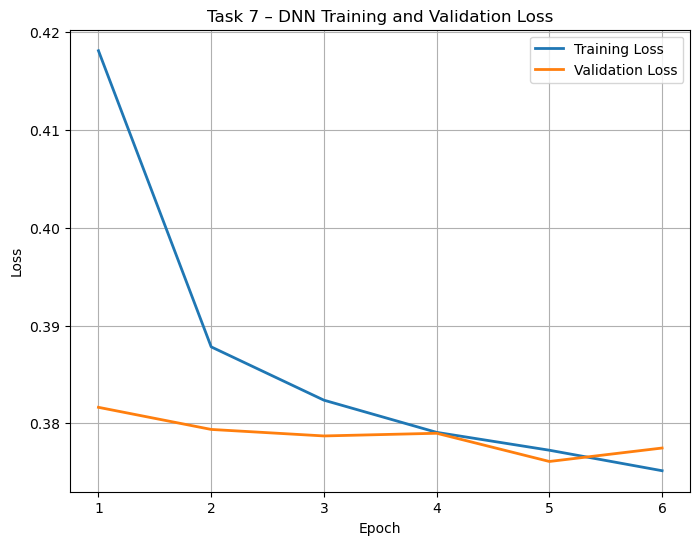

The curves show whether the model is learning properly. Both training and validation loss decrease and stabilize.


In [16]:
plt.figure(figsize=(8, 6))
plt.plot(training_history_df['epoch'], training_history_df['loss'], label='Training Loss', lw=2)
plt.plot(training_history_df['epoch'], training_history_df['val_loss'], label='Validation Loss', lw=2)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Task 7 – DNN Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.savefig('task7_loss_curve.png')
plt.show()

print("The curves show whether the model is learning properly. Both training and validation loss decrease and stabilize.")


## 22. FINAL TEST PREDICTIONS

In [17]:
print("Generating test set predictions...")
t0 = time.time()
y_prob = final_model.predict(X_test_scaled, batch_size=1024, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)
print(f"Predictions generated in {time.time()-t0:.2f}s.")


Generating test set predictions...


 1/79 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 588us/step


Predictions generated in 0.08s.


## 23. EVALUATION METRICS

In [18]:
accuracy = accuracy_score(y_test_encoded, y_pred)
precision = precision_score(y_test_encoded, y_pred, zero_division=0)
recall = recall_score(y_test_encoded, y_pred, zero_division=0)
f1 = f1_score(y_test_encoded, y_pred, zero_division=0)
auc = roc_auc_score(y_test_encoded, y_prob)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC-AUC: {auc:.4f}")


Accuracy: 0.5991
Precision: 0.9829
Recall: 0.2017
F1-score: 0.3347
ROC-AUC: 0.8945


## 24. CLASSIFICATION REPORT

In [19]:
class_names = label_encoder.classes_.astype(str)
print(classification_report(y_test_encoded, y_pred, target_names=class_names))


              precision    recall  f1-score   support

           0       0.56      1.00      0.71     40000
           1       0.98      0.20      0.33     40000

    accuracy                           0.60     80000
   macro avg       0.77      0.60      0.52     80000
weighted avg       0.77      0.60      0.52     80000



## 25. CONFUSION MATRIX

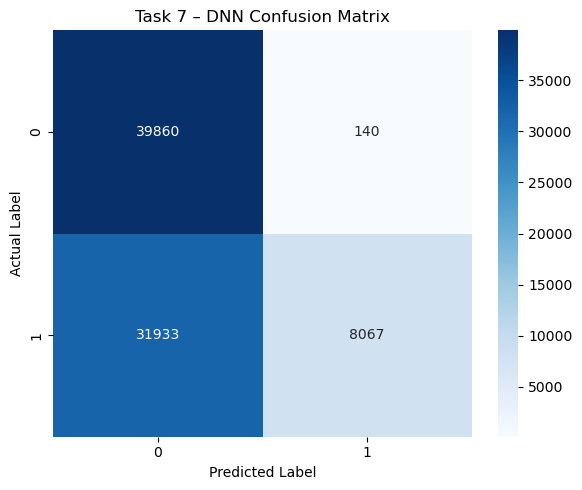

Numerical Confusion Matrix:
[[39860   140]
 [31933  8067]]


In [20]:
cm = confusion_matrix(y_test_encoded, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Task 7 – DNN Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('task7_confusion_matrix.png')
plt.show()

print("Numerical Confusion Matrix:")
print(cm)


## 26. ROC CURVE

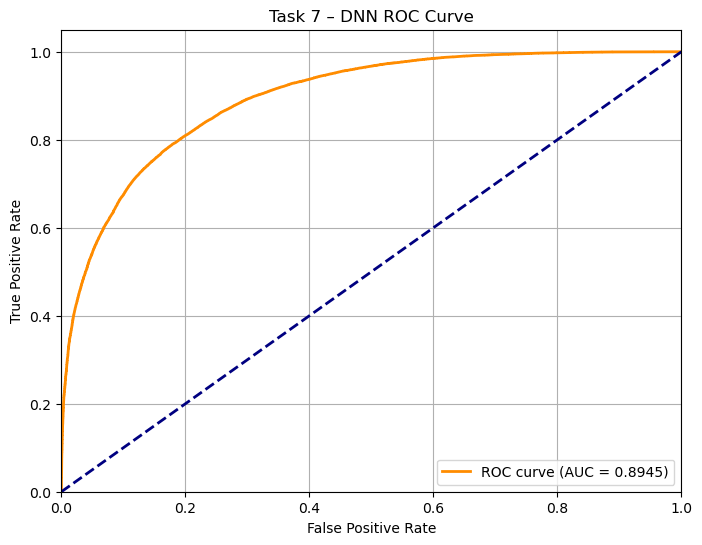

In [21]:
fpr, tpr, thresholds = roc_curve(y_test_encoded, y_prob)
roc_auc = roc_auc_score(y_test_encoded, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Task 7 – DNN ROC Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.savefig('task7_roc_curve.png')
plt.show()


## 27. DNN EVALUATION REPORT

In [22]:
evaluation_dict = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Score': [accuracy, precision, recall, f1, auc]
}
task7_evaluation_report = pd.DataFrame(evaluation_dict)
task7_evaluation_report.to_csv('task7_evaluation_report.csv', index=False)
display(task7_evaluation_report)


,Metric,Score
0,Accuracy,0.599087
1,Precision,0.982941
2,Recall,0.201675
3,F1-Score,0.334682
4,ROC-AUC,0.894479


## 28. TASK 6 vs TASK 7 COMPARISON

In [23]:
try:
    task6_report = pd.read_csv('task6_model_comparison_report.csv')
    if 'Type' not in task6_report.columns:
        task6_report['Type'] = 'Traditional ML'
    
    dnn_row = pd.DataFrame({
        'Model': ['Deep Neural Network'],
        'Accuracy': [accuracy],
        'Precision': [precision],
        'Recall': [recall],
        'F1-Score': [f1],
        'AUC': [auc],
        'Type': ['Deep Learning']
    })
    
    cols_to_keep = ['Model', 'Type', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC']
    task6_subset = task6_report[[c for c in cols_to_keep if c in task6_report.columns]].copy()
    if 'Type' not in task6_subset.columns:
        task6_subset['Type'] = 'Traditional ML'
        
    task6_vs_task7_comparison = pd.concat([task6_subset, dnn_row], ignore_index=True)
    final_cols = [c for c in cols_to_keep if c in task6_vs_task7_comparison.columns]
    task6_vs_task7_comparison = task6_vs_task7_comparison[final_cols]
    
    task6_vs_task7_comparison.to_csv('task6_vs_task7_comparison.csv', index=False)
    display(task6_vs_task7_comparison)
    comparison_available = True
    
except FileNotFoundError:
    print("Task 6 comparison file was not found. DNN evaluation has been completed.")
    comparison_available = False


,Model,Type,Accuracy,Precision,Recall,F1-Score,AUC
0,Logistic Regression,Traditional ML,0.790088,0.814627,0.790088,0.785913,0.906619
1,SVM,Traditional ML,0.788550,0.814461,0.788550,0.784103,0.906447
2,XGBoost,Traditional ML,0.785512,0.808811,0.785512,0.781389,0.901895
3,Random Forest,Traditional ML,0.756575,0.801428,0.756575,0.747170,0.892083
4,Decision Tree,Traditional ML,0.731500,0.736946,0.731500,0.729948,0.784107
5,Deep Neural Network,Deep Learning,0.599087,0.982941,0.201675,0.334682,0.894479


## 29. PERFORMANCE COMPARISON GRAPH

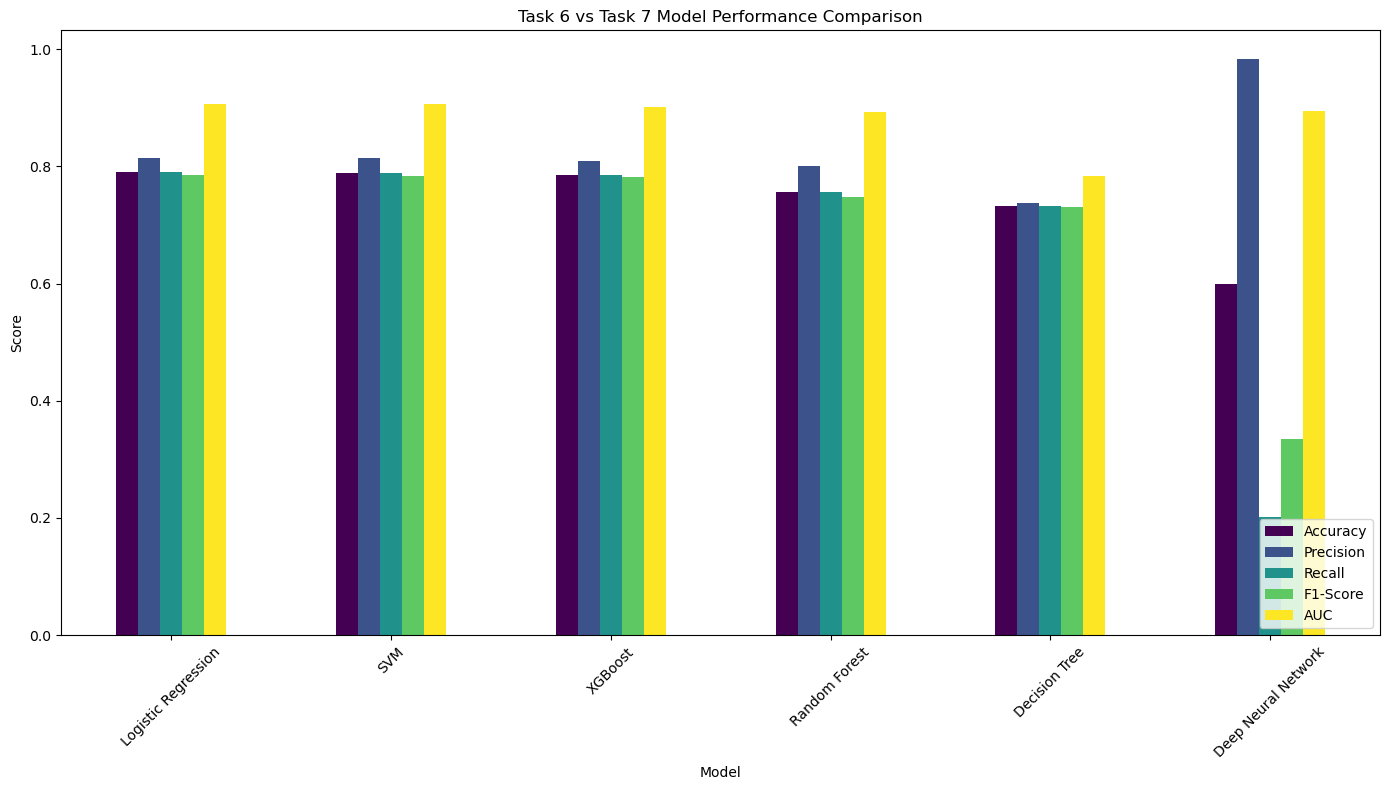

In [24]:
if comparison_available:
    metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC']
    plot_df = task6_vs_task7_comparison.set_index('Model')
    available_metrics = [m for m in metrics_to_plot if m in plot_df.columns]
    plot_df[available_metrics].plot(kind='bar', figsize=(14, 8), colormap='viridis')
    plt.title('Task 6 vs Task 7 Model Performance Comparison')
    plt.ylabel('Score')
    plt.xticks(rotation=45)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.savefig('task6_vs_task7_comparison.png')
    plt.show()


## 30. HYPERPARAMETER REPORT

In [25]:
print("task7_hyperparameter_report.csv has been saved successfully.")
display(hyperparameter_report)


task7_hyperparameter_report.csv has been saved successfully.


,Configuration,Hidden Layers,Neurons,Dropout,Learning Rate,Batch Size,Epochs,Validation Accuracy,Validation Loss
0,Config 1,128 -> 64 -> 32,"128,64,32",0.3,0.001,256,3,0.816333,0.401850
1,Config 2,128 -> 64 -> 32,"128,64,32",0.5,0.001,256,3,0.811333,0.406704
2,Config 3,64 -> 32,"64,32",0.3,0.001,256,3,0.816000,0.401215


## 31. SAVE DNN MODEL

In [26]:
final_model.save("task7_dnn_model.keras")
print("Saved final_model as task7_dnn_model.keras")

try:
    final_model.save("task7_dnn_model.h5")
    print("Saved task7_dnn_model.h5")
except Exception as e:
    print(f"H5 format note: {e}")


Saved final_model as task7_dnn_model.keras
Saved task7_dnn_model.h5


## 32. SAVE SUPPORTING OBJECTS

In [27]:
print("task7_scaler.pkl and task7_label_encoder.pkl have been saved successfully.")


task7_scaler.pkl and task7_label_encoder.pkl have been saved successfully.


## 33. FINAL TASK 7 REPORT

In [28]:
print("========================================================")
print("TASK 7 – FINAL RESULTS")
print("========================================================")
print(f"Dataset:\nProduct Review Sentiment Dataset\n")
print(f"Training Samples:\n{X_train.shape[0]}\n")
print(f"Testing Samples:\n{X_test.shape[0]}\n")
print(f"Number of Input Features:\n{X_train.shape[1]}\n")
print(f"Number of Classes:\n{len(np.unique(y_train_encoded))}\n")
print(f"DNN Architecture:\n{best_config['Hidden Layers']} -> Output\n")
print(f"Dropout:\n{best_config['Dropout']}\n")
print(f"Batch Size:\n{final_batch_size}\n")
print(f"Learning Rate:\n{best_config['Learning Rate']}\n")
print(f"Epochs Trained:\n{epochs_trained}\n")
print("--------------------------------------------------------")
print("DNN PERFORMANCE")
print("--------------------------------------------------------")
print(f"Accuracy:\n{accuracy:.4f}\n")
print(f"Precision:\n{precision:.4f}\n")
print(f"Recall:\n{recall:.4f}\n")
print(f"F1-Score:\n{f1:.4f}\n")
print(f"ROC-AUC:\n{auc:.4f}\n")
print(f"Training Time:\n{training_time:.2f}s\n")
print("========================================================")


TASK 7 – FINAL RESULTS
Dataset:
Product Review Sentiment Dataset

Training Samples:
319996

Testing Samples:
80000

Number of Input Features:
100

Number of Classes:
2

DNN Architecture:
128 -> 64 -> 32 -> Output

Dropout:
0.3

Batch Size:
512

Learning Rate:
0.001

Epochs Trained:
6

--------------------------------------------------------
DNN PERFORMANCE
--------------------------------------------------------
Accuracy:
0.5991

Precision:
0.9829

Recall:
0.2017

F1-Score:
0.3347

ROC-AUC:
0.8945

Training Time:
3.83s



## 34. REQUIRED DELIVERABLE CHECK

In [29]:
deliverables = [
    "task7_dnn_model.keras",
    "task7_training_history.csv",
    "task7_accuracy_curve.png",
    "task7_loss_curve.png",
    "task7_evaluation_report.csv",
    "task7_hyperparameter_report.csv",
    "task7_confusion_matrix.png",
    "task7_roc_curve.png",
    "task6_vs_task7_comparison.csv",
    "task7_scaler.pkl",
    "task7_label_encoder.pkl"
]

print("Required Deliverable Check:")
for file in deliverables:
    if os.path.exists(file):
        print(f"[✓] {file}")
    else:
        print(f"[ ] {file} (Missing)")


Required Deliverable Check:
[✓] task7_dnn_model.keras
[✓] task7_training_history.csv
[✓] task7_accuracy_curve.png
[✓] task7_loss_curve.png
[✓] task7_evaluation_report.csv
[✓] task7_hyperparameter_report.csv
[✓] task7_confusion_matrix.png
[✓] task7_roc_curve.png
[✓] task6_vs_task7_comparison.csv
[✓] task7_scaler.pkl
[✓] task7_label_encoder.pkl


## 35. CONCLUSION
A Deep Neural Network was designed for product review sentiment classification.
The DNN used the optimized features generated in Task 5.
The model was trained and validated using separate data.
Dropout and early stopping were used to control overfitting.
The model was evaluated using accuracy, precision, recall, F1-score and ROC-AUC.
Confusion matrix and ROC curve were generated.
The DNN was compared with traditional ML models from Task 6.
The final DNN model was saved for future integration.

In [30]:
print("==================================================")
print("✓ TASK 7 COMPLETED SUCCESSFULLY")
print("==================================================")


✓ TASK 7 COMPLETED SUCCESSFULLY
